# Modelo de Riesgo: Regresión Logística

Este notebook entrena y evalúa el modelo que el servidor MCP consultará para puntuar una transacción. Trabaja sobre el dataset que produce `scripts/prepare_dataset.py`, cuyas variables fueron decididas en `01_eda.ipynb`.

## 1. Objetivo y criterios

El modelo debe cumplir tres condiciones que vienen del caso de uso:

1. **Ser explicable.** Cuando se bloquea una tarjeta hay que poder decirle al cliente y al auditor por qué. Una regresión logística asigna un peso a cada variable, y esos pesos se leen directamente.

2. **Producir un puntaje entre 0 y 1**, no solo una etiqueta, para que el analista distinga un caso dudoso de uno evidente.

3. **Ser reproducible en el servidor sin dependencias.** Una regresión logística se evalúa con una multiplicación y una función sigmoide, así que el servidor puede calcularla en Python puro.

La evaluación se hace con la **partición temporal**, se entrena con las transacciones de enero 2019 a junio 2020 y se evalúa con las de junio a diciembre 2020.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

DATA = Path("..") / "data" / "processed"
RAW = Path("..") / "data" / "raw"

AZUL, ROJO, GRIS = "#3b6fa8", "#c1443f", "#8a8f98"

plt.rcParams.update({
    "figure.figsize": (7.2, 3.4),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
    "font.size": 9,
})
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 2. Carga del dataset procesado

In [2]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")

FEATURES = [c for c in train.columns if c != "is_fraud"]
X_train, y_train = train[FEATURES], train["is_fraud"]
X_test, y_test = test[FEATURES], test["is_fraud"]

print(f"entrenamiento: {len(train):,} filas   fraude: {y_train.mean():.4%}   fraudes: {y_train.sum():,}")
print(f"prueba:        {len(test):,} filas   fraude: {y_test.mean():.4%}   fraudes: {y_test.sum():,}")
print(f"variables: {len(FEATURES)}")

entrenamiento: 1,296,675 filas   fraude: 0.5789%   fraudes: 7,506
prueba:        555,719 filas   fraude: 0.3860%   fraudes: 2,145
variables: 24


In [3]:
# Días que cubre la partición de prueba, para expresar las alertas en volumen diario.
fechas = pd.read_csv(
    RAW / "fraudTest.csv", usecols=["trans_date_trans_time"], parse_dates=["trans_date_trans_time"]
)["trans_date_trans_time"]
DIAS_PRUEBA = (fechas.max() - fechas.min()).days
print(f"la partición de prueba cubre {DIAS_PRUEBA} días "
      f"({len(test) / DIAS_PRUEBA:,.0f} transacciones por día)")

la partición de prueba cubre 193 días (2,879 transacciones por día)


Hay **24 variables** y una etiqueta. La partición de prueba tiene una tasa de fraude de 0.386%, menor que la de entrenamiento (0.579%).

Conocer que el período de prueba cubre **193 días con unas 2,879 transacciones diarias** permite traducir después las métricas a algo que un centro de monitoreo entiende: cuántas alertas al día tendría que revisar un analista.

## 3. Entrenamiento

Dos piezas acompañan a la regresión logística:

- **`StandardScaler`** convierte cada variable a media 0 y desviación 1. Es necesario porque las variables están en escalas muy distintas (`minutes_since_prev` llega a decenas de miles y `is_night` vale 0 o 1); sin escalar, el optimizador converge mal y los coeficientes no serían comparables entre sí.
- **`class_weight="balanced"`** hace que cada fila de fraude pese, en el cálculo del error, tanto como el conjunto de las legítimas que le corresponden. Sin esto el modelo aprendería que decir siempre "legítima" es una estrategia casi perfecta.

In [4]:
modelo = Pipeline([
    ("escalado", StandardScaler()),
    ("regresion", LogisticRegression(
        class_weight="balanced",   # compensa que solo 0.58% de las filas sean fraude
        max_iter=1000,
        random_state=42,
    )),
])

%time modelo.fit(X_train, y_train)

CPU times: user 20.7 s, sys: 2.43 s, total: 23.2 s
Wall time: 6.07 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalado', ...), ('regresion', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['log_amt','hour','is_night',...,'cat_shopping_net','cat_shopping_pos', 'cat_travel']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


El entrenamiento toma unos seis segundos sobre 1.3 millones de filas.

## 4. Evaluación

In [5]:
prob = modelo.predict_proba(X_test)[:, 1]

print(f"ROC-AUC: {roc_auc_score(y_test, prob):.4f}")
print(f"PR-AUC (precisión promedio): {average_precision_score(y_test, prob):.4f}")
print(f"PR-AUC de un modelo aleatorio: {y_test.mean():.4f}")

ROC-AUC: 0.9395
PR-AUC (precisión promedio): 0.1826


PR-AUC de un modelo aleatorio: 0.0039


In [6]:
pred_05 = (prob >= 0.5).astype(int)
print(classification_report(y_test, pred_05, target_names=["legítima", "fraude"], digits=4))
print("matriz de confusión (filas = real, columnas = predicho)")
print(pd.DataFrame(
    confusion_matrix(y_test, pred_05),
    index=["real legítima", "real fraude"], columns=["pred legítima", "pred fraude"],
).to_string())

              precision    recall  f1-score   support

    legítima     0.9996    0.8493    0.9183    553574
      fraude     0.0227    0.9030    0.0443      2145

    accuracy                         0.8495    555719
   macro avg     0.5111    0.8762    0.4813    555719
weighted avg     0.9958    0.8495    0.9149    555719

matriz de confusión (filas = real, columnas = predicho)
               pred legítima  pred fraude
real legítima         470134        83440
real fraude              208         1937


In [7]:
trivial = np.zeros_like(y_test)
print(f"exactitud del modelo trivial 'todo legítimo': {(trivial == y_test).mean():.4%}")
print(f"fraudes detectados por el modelo trivial: 0 de {y_test.sum():,}")
print(f"exactitud del modelo entrenado con umbral 0.5: {(pred_05 == y_test).mean():.4%}")
print(f"fraudes detectados con umbral 0.5: {int(((pred_05 == 1) & (y_test == 1)).sum()):,} de {y_test.sum():,}")

exactitud del modelo trivial 'todo legítimo': 99.6140%
fraudes detectados por el modelo trivial: 0 de 2,145
exactitud del modelo entrenado con umbral 0.5: 84.9478%
fraudes detectados con umbral 0.5: 1,937 de 2,145


Los dos números miden cosas distintas.

- **ROC-AUC = 0.9395** parece excelente, y suele ser la métrica que se reporta. Pero con clases tan desbalanceadas es engañosa, mide qué tan bien se ordenan las transacciones, y acertar el orden es fácil cuando el 99.6% pertenece a una sola clase.
- **PR-AUC = 0.1826** es la métrica honesta. Un modelo aleatorio obtendría 0.0039 (la prevalencia), así que el modelo es **47 veces mejor que el azar**, pero está lejos de ser perfecto.

Con el umbral por omisión de 0.5 el modelo detecta el **90.3% de los fraudes**, pero solo el **2.27% de sus alertas son fraude real**: 85,377 alertas para 1,937 fraudes. Un analista tendría que revisar 442 casos por día. Es inutilizable en la práctica.

El contraste con el modelo trivial deja más clara la diferencia sobre la exactitud, predecir "todo legítimo"
alcanza **99.61%** de exactitud sin detectar un solo fraude, mientras el modelo entrenado con umbral 0.5 baja a **84.95%** y detecta 1,937. La exactitud premia al modelo que no sirve.

## 5. Elección del umbral

El modelo no decide; entrega una probabilidad. El umbral es una decisión de negocio (cuántas alertas puede revisar el equipo y cuánto fraude se está dispuesto a dejar pasar).

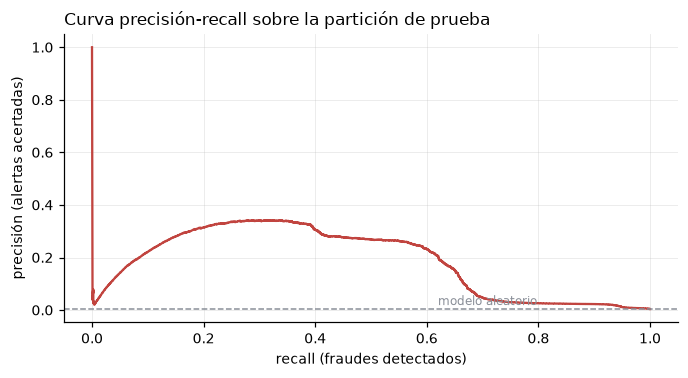

In [8]:
precision, recall, cortes = precision_recall_curve(y_test, prob)

fig, ax = plt.subplots()
ax.plot(recall, precision, color=ROJO, linewidth=1.5)
ax.axhline(y_test.mean(), color=GRIS, linewidth=1, linestyle="--")
ax.annotate("modelo aleatorio", (0.62, y_test.mean() + 0.015), color=GRIS, fontsize=8)
ax.set_xlabel("recall (fraudes detectados)")
ax.set_ylabel("precisión (alertas acertadas)")
ax.set_title("Curva precisión-recall sobre la partición de prueba", loc="left")
plt.show()

In [9]:
filas = []
for umbral in [0.5, 0.7, 0.8, 0.9, 0.95, 0.97, 0.99]:
    pred = (prob >= umbral).astype(int)
    alertas = int(pred.sum())
    aciertos = int(((pred == 1) & (y_test == 1)).sum())
    filas.append({
        "umbral": umbral,
        "alertas": alertas,
        "alertas_por_dia": alertas / DIAS_PRUEBA,
        "fraudes_detectados": aciertos,
        "precision": aciertos / alertas if alertas else np.nan,
        "recall": aciertos / int(y_test.sum()),
    })

tabla = pd.DataFrame(filas).set_index("umbral")
tabla["f1"] = 2 * tabla["precision"] * tabla["recall"] / (tabla["precision"] + tabla["recall"])
tabla.round(4)

,alertas,alertas_por_dia,fraudes_detectados,precision,recall,f1
umbral,,,,,,
0.5000,85377,442.3679,1937,0.0227,0.9030,0.0443
0.7000,41257,213.7668,1546,0.0375,0.7207,0.0712
0.8000,12231,63.3731,1418,0.1159,0.6611,0.1973
0.9000,5031,26.0674,1245,0.2475,0.5804,0.3470
0.9500,3501,18.1399,969,0.2768,0.4517,0.3433
0.9700,2842,14.7254,864,0.3040,0.4028,0.3465
0.9900,1953,10.1192,666,0.3410,0.3105,0.3250


La tabla muestra el intercambio con claridad. Al subir el umbral de 0.5 a 0.9 las alertas caen de 442 a **26 por día** y la precisión sube de 2.3% a **24.8%**, a cambio de bajar el recall de 90% a 58%. Más allá de 0.9 se sigue perdiendo recall sin ganar mucha precisión: en 0.99 apenas llega al 34% de precisión pero detecta solo el 31% de los fraudes.

**Decisión**: **Se elige el umbral 0.90**, que además es donde el F1 alcanza su máximo (0.347). Con él, uno de cada cuatro casos que el analista revisa es fraude real y el volumen diario es manejable.

In [10]:
UMBRAL = 0.90
pred = (prob >= UMBRAL).astype(int)

print(classification_report(y_test, pred, target_names=["legítima", "fraude"], digits=4))
print("matriz de confusión (filas = real, columnas = predicho)")
print(pd.DataFrame(
    confusion_matrix(y_test, pred),
    index=["real legítima", "real fraude"], columns=["pred legítima", "pred fraude"],
).to_string())

fn = int(((pred == 0) & (y_test == 1)).sum())
fp = int(((pred == 1) & (y_test == 0)).sum())
print(f"\nfraudes no detectados: {fn:,}   falsas alarmas: {fp:,} ({fp / DIAS_PRUEBA:,.0f} por día)")

              precision    recall  f1-score   support

    legítima     0.9984    0.9932    0.9958    553574
      fraude     0.2475    0.5804    0.3470      2145

    accuracy                         0.9916    555719
   macro avg     0.6229    0.7868    0.6714    555719
weighted avg     0.9955    0.9916    0.9933    555719

matriz de confusión (filas = real, columnas = predicho)
               pred legítima  pred fraude
real legítima         549788         3786
real fraude              900         1245

fraudes no detectados: 900   falsas alarmas: 3,786 (20 por día)


Con el umbral en 0.90, sobre los 193 días de prueba: **1,245 fraudes detectados de 2,145**, 900 sin detectar y 3,786 falsas alarmas, es decir unas 20 al día. La exactitud queda en 99.16%, todavía por debajo del 99.61% del modelo trivial.

Queda claro también que el modelo **no reemplaza al analista** (deja pasar el 42% de los fraudes). Su función es priorizar, y por eso el servidor combinará este puntaje con reglas explícitas.

## 6. Interpretación de los coeficientes

Como las variables están estandarizadas, los coeficientes son comparables entre sí, un valor positivo grande significa que esa variable empuja el riesgo hacia arriba.

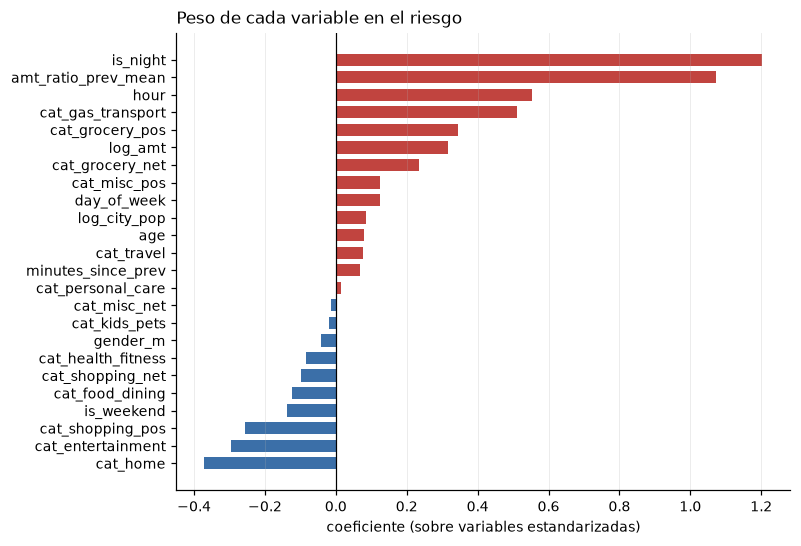

is_night               1.2030
amt_ratio_prev_mean    1.0720
hour                   0.5540
cat_gas_transport      0.5110
cat_grocery_pos        0.3450
log_amt                0.3170
cat_grocery_net        0.2360
cat_misc_pos           0.1250
day_of_week            0.1230
log_city_pop           0.0860
age                    0.0810
cat_travel             0.0760
minutes_since_prev     0.0690
cat_personal_care      0.0140
cat_misc_net          -0.0150
cat_kids_pets         -0.0200
gender_m              -0.0430
cat_health_fitness    -0.0850
cat_shopping_net      -0.0990
cat_food_dining       -0.1250
is_weekend            -0.1390
cat_shopping_pos      -0.2550
cat_entertainment     -0.2950
cat_home              -0.3710

intercepto: -2.062


In [11]:
coeficientes = pd.Series(
    modelo.named_steps["regresion"].coef_[0], index=FEATURES
).sort_values()

fig, ax = plt.subplots(figsize=(7.2, 5.4))
colores = [ROJO if v > 0 else AZUL for v in coeficientes.values]
ax.barh(coeficientes.index, coeficientes.values, color=colores, height=0.7)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("coeficiente (sobre variables estandarizadas)")
ax.grid(axis="y", visible=False)
ax.set_title("Peso de cada variable en el riesgo", loc="left")
plt.show()

print(coeficientes.sort_values(ascending=False).round(3).to_string())
print(f"\nintercepto: {modelo.named_steps['regresion'].intercept_[0]:.3f}")

Los pesos confirman algunos hallazgos del EDA y agregan un par de aspectos instructivos:

- **`is_night` (1.203) y `amt_ratio_prev_mean` (1.072)** son las dos variables dominantes. Son exactamente las dos señales más fuertes que encontró el análisis exploratorio: la franja de 22:00 a 03:59 y el gasto desproporcionado frente al historial de la tarjeta. `hour` (0.554) refuerza lo mismo.
- **`log_amt` (0.317) pesa menos de lo esperado**, aunque el monto era el mejor separador visto en el EDA. La probable razón de esto es que la relación entre monto y riesgo **no es lineal ni monótona** (el fraude se concentra en montos altos *y* en montos muy pequeños), y un coeficiente único no puede representar dos zonas; además `amt_ratio_prev_mean` ya captura buena parte de esa información.
- **`log_city_pop` (0.086), `age` (0.081) y `gender_m` (-0.043)** son prácticamente nulos, como se anticipaba en el EDA. Se confirma que no aportan.
- **`minutes_since_prev` (0.069)** casi desaparece, pese a que las medianas por clase diferían. Su señal queda absorbida por las variables anteriores una vez que están en el modelo.
- Entre las categorías, `gas_transport` (0.511) y `grocery_pos` (0.345) suben el riesgo, mientras `home` (-0.371) y `entertainment` (-0.295) lo bajan. Llama la atención que `shopping_net`, la categoría con más fraude del EDA (1.76%), tenga un coeficiente ligeramente negativo (-0.099); sus fraudes ocurren de noche y con montos altos, así que esas variables ya explican el riesgo y al one-hot solo le queda lo que sobra. **Un coeficiente no es la tasa de fraude de la categoría**, sino su efecto una vez descontado el resto.

## 7. Conclusión

La configuración se define y queda implementada en `scripts/train_model.py`.

| Elemento | Valor |
|---|---|
| Variables | las 24 de `data/processed/` |
| Escalado | `StandardScaler` |
| Modelo | `LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)` |
| Umbral de decisión | **0.90** |
| Validación | partición temporal (entrena 2019-01 → 2020-06, evalúa 2020-06 → 2020-12) |
| Desempeño | ROC-AUC = 0.9395, PR-AUC = 0.1826, precisión = 0.2475, recall = 0.5804 |

El script exporta estos coeficientes, el escalado y el umbral a `artifacts/model.json`, y verifica que una reimplementación en Python puro produzca el mismo puntaje. Con eso el servidor MCP puede puntuar transacciones sin instalar scikit-learn.